# Fund Detective — Professor Solutions (v2)

**Your role:** You are an investment advisor at a wealth management firm. Your firm has received historical returns for three anonymous equity funds, **Fund A**, **Fund B**, and **Fund C**. Their managers have not disclosed their strategies or portfolios.

A client wants to understand what these funds actually invest in, which risks they take, and whether any of them deserves a place in an investment portfolio. Your job is to provide an evidence-based recommendation.

**Data:** The file supplied by your firm contains **daily returns** for the three funds and an S&P 500 proxy (SPY) from 2015 to 2025, expressed in USD. The publicly available Fama–French factors and industry portfolios supplied below contain **monthly returns**.

**Deliverable:** Submit this notebook with all calculations, charts and answers, plus a concise recommendation for the client. Do not assume that high historical returns imply superior skill or future performance.

**Instructor copy — includes complete worked code and financial interpretations. Keep confidential.**

## 0. Data and market information

The client has supplied an anonymized file of daily fund and benchmark returns. Publicly available monthly Fama–French factors and industry portfolio returns are provided below.

**Your client asks:**

> Before you analyze my investments, please ensure that the data from the different sources are comparable and that the conclusions you draw are based on consistent observations.

Explain any data limitations relevant to your advice.

In [ ]:
%pip -q install pandas-datareader statsmodels matplotlib

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pandas_datareader import data as web
from IPython.display import display 
import pandas_datareader.famafrench as ff_module    

## DESCARGA DE LOS DATOS PARA EL EJERCICIO: ELIMINAR DEL NOTEBOOK DE ESTUDIANTES

In [ ]:

# Download adjusted daily prices
tickers = ['FBGRX', 'FDVLX', 'FIEUX', 'SPY']

prices = yf.download(
    tickers,
    start='2014-12-01',
    end='2026-01-01',
    auto_adjust=True,
    progress=False
)['Close']

# Calculate daily returns
returns = prices.pct_change(fill_method=None)
returns = returns.loc['2015-01-01':'2025-12-31'].dropna()

# Hide the identities of the funds
returns = returns.rename(columns={
    'FBGRX': 'Fund A',
    'FDVLX': 'Fund B',
    'FIEUX': 'Fund C'
})

returns = returns[['Fund A', 'Fund B', 'Fund C', 'SPY']]

# Save and download
filename = '../data/fund_detective_anonymous_daily_returns_2015_2025.csv'
returns.to_csv(filename, index_label='Date')

display(returns.head())
print(f'Observations: {len(returns)}')



In [3]:
# Load the anonymized fund and benchmark returns supplied by your firm.
# In Colab, upload the CSV to the working directory first.
daily_returns = pd.read_csv(
    '../data/fund_detective_anonymous_daily_returns_2015_2025.csv',
    index_col='Date', parse_dates=True
)
display(daily_returns.head())

,Fund A,Fund B,Fund C,SPY
Date,,,,
2015-01-02,-0.001461,-0.001766,-0.009073,-0.000535
2015-01-05,-0.017125,-0.017955,-0.018598,-0.018059
2015-01-06,-0.011467,-0.010898,-0.009329,-0.009419
2015-01-07,0.015969,0.010563,0.001471,0.012461
2015-01-08,0.018980,0.016129,0.012342,0.017745


In [5]:
# Download the monthly Fama–French and industry datasets.
# The original sources report returns in percent; convert to decimals.


ff_module._URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/'

def get_french_data(dataset):
    df = web.DataReader(
        dataset, 'famafrench',
        start='2015-01-01',
        end='2025-12-31'
    )[0].copy()

    df.columns = df.columns.str.strip()
    return df / 100

ff_us = get_french_data('F-F_Research_Data_Factors')
ff_europe = get_french_data('Europe_3_Factors')
industries_us = get_french_data('5_Industry_Portfolios')

print('US factors:', ff_us.columns.tolist())
print('European factors:', ff_europe.columns.tolist())
print('US industry portfolios:', industries_us.columns.tolist())

US factors: ['Mkt-RF', 'SMB', 'HML', 'RF']
European factors: ['Mkt-RF', 'SMB', 'HML', 'RF']
US industry portfolios: ['Cnsmr', 'Manuf', 'HiTec', 'Hlth', 'Other']


In [ ]:
# # Save Fama-French factors and industry portfolios
# ff_us.to_csv('../data/ff_us.csv')
# ff_europe.to_csv('../data/ff_europe.csv')
# industries_us.to_csv('../data/industries_us.csv')

### Instructor convention — monthly returns
For this teaching exercise, **treat the supplied daily returns as approximately logarithmic** and obtain monthly returns by **summing daily observations**. The downloaded Fama–French monthly factors are reported as simple returns; they are used as small-return approximations alongside the monthly sums. The input CSV originated from simple daily returns, so the summation is an approximation, **not an exact log-return aggregation**. For exact aggregation of simple returns, use compounding. We use this convention deliberately for the course, but retain this qualification for the instructor.

The date index is converted to monthly `PeriodIndex` values for alignment.

In [16]:
# Convert daily returns into monthly returns
monthly = daily_returns.resample('ME').sum()

# Select the period 2015–2025
monthly = monthly.loc['2015':'2025']

# Use monthly dates instead of daily dates
monthly.index = monthly.index.to_period('M')

# Select funds and market benchmark
funds = ['Fund A', 'Fund B', 'Fund C']
market = 'SPY'

# Display results
print('Monthly observations:', len(monthly))
display(monthly.head())

# Check common observations with Fama-French factors
print('Common months with Fama-French factors:',
      len(monthly.index.intersection(ff_us.index)))

Monthly observations: 132


,Fund A,Fund B,Fund C,SPY
Date,,,,
2015-01,-0.006715,-0.025175,0.014239,-0.028986
2015-02,0.062896,0.056413,0.060726,0.055075
2015-03,-0.000446,0.001008,-0.021313,-0.014992
2015-04,-0.008197,0.004341,0.049289,0.010077
2015-05,0.023630,0.021534,0.015316,0.013211


Common months with Fama-French factors: 132


### 1. Fund Performance and Risk Analysis

Before making any investment decision, I would like to understand how the three funds have performed compared with the S&P 500.

Please prepare an analysis addressing the following questions:

1. What are the **annualized returns, annualized volatilities, maximum drawdowns, and Sharpe ratios** of the three funds and the S&P 500?
2. How would an initial investment of **$100** in each fund and the S&P 500 have evolved over the period?
3. How strongly are the funds' returns correlated with the S&P 500?
4. Which fund has delivered the highest return? Which has offered the best risk-adjusted performance?
5. Which fund has experienced the largest losses during market downturns?
6. Based on these results, which fund would you consider most attractive, and what additional information would you need before recommending it?

Rentabilidad y Riesgo

In [17]:
# Select funds and benchmark
assets = funds + [market]
returns = daily_returns.loc['2015':'2025', assets]

# Maximum drawdown
def max_drawdown(r):
    wealth = np.exp(r.cumsum())
    return (wealth / wealth.cummax() - 1).min()

# Annualized performance
performance = pd.DataFrame({
    'Annual return': np.exp(returns.mean() * 252) - 1,
    'Annual volatility': returns.std() * np.sqrt(252),
    'Max drawdown': returns.apply(max_drawdown),
    'Correlation with SPY': returns.corr()[market]
})

display(performance.round(3))

,Annual return,Annual volatility,Max drawdown,Correlation with SPY
Fund A,0.215,0.231,-0.391,0.922
Fund B,0.121,0.216,-0.463,0.877
Fund C,0.088,0.176,-0.365,0.758
SPY,0.153,0.178,-0.317,1.000


Wealth Evolution

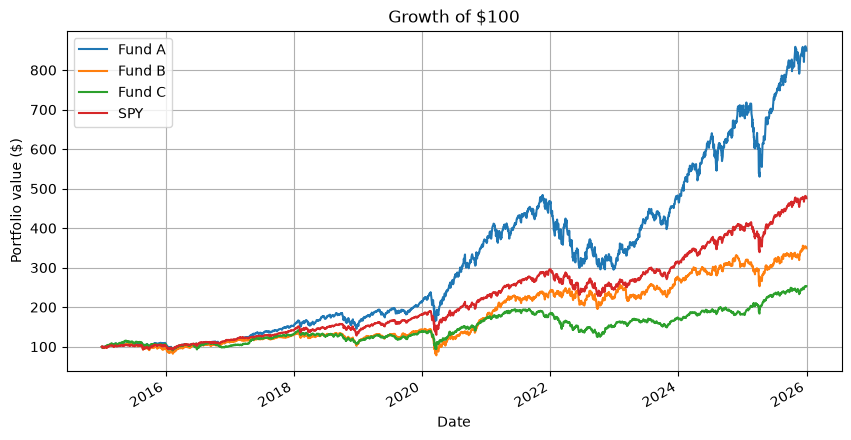

In [18]:
# Growth of $100
wealth = 100 * np.exp(returns.cumsum())

wealth.plot(figsize=(10, 5), title='Growth of $100')

plt.ylabel('Portfolio value ($)')
plt.grid()
plt.show()

Sharpe Ratio

In [19]:
# Combine monthly returns with the risk-free rate
data = monthly[assets].join(ff_us['RF'], how='inner')

# Monthly excess returns
excess = data[assets].sub(data['RF'], axis=0)

# Annualized Sharpe ratio
sharpe = excess.mean() / excess.std() * np.sqrt(12)

display(sharpe.round(3))

Fund A    0.916
Fund B    0.464
Fund C    0.410
SPY       0.841
dtype: float64

## Conclusions: Fund Performance Analysis (2015–2025)

- **Fund A – Best risk-adjusted performance.** Achieves the highest annualized return (21.5%) and Sharpe ratio (0.916), outperforming SPY. However, it also has the highest volatility (23.1%) and a strong correlation with the market (0.922).

- **Fund B – Underperforms the benchmark.** Delivers a lower return (12.1%) than SPY (15.3%), despite higher volatility and a larger maximum drawdown (−46.3%). Its Sharpe ratio (0.464) is also considerably lower.

- **Fund C – Lower market exposure.** Has the lowest correlation with SPY (0.758), suggesting potential diversification benefits. However, its annualized return (8.8%) and Sharpe ratio (0.410) are the lowest.

- **SPY – Strong benchmark performance.** Offers a favorable combination of return (15.3%), volatility (17.8%) and Sharpe ratio (0.841). It also experiences the smallest maximum drawdown (−31.7%).

### Key Takeaways

1. **Higher returns come with additional risk:** Fund A outperforms SPY but exhibits greater volatility and larger historical losses.
2. **Risk-adjusted performance matters:** Fund A has the highest Sharpe ratio, while Funds B and C underperform SPY.
3. **Lower correlation does not guarantee better diversification:** Fund C may provide diversification benefits, but these must be evaluated at the portfolio level.
4. **Outperformance does not necessarily imply alpha:** Fund A's higher returns may reflect greater exposure to systematic risk factors.

**Next step:** Estimate CAPM and Fama–French factor regressions to determine whether the funds generate statistically significant alpha after controlling for their risk exposures.

## 2. Understanding Market Risk: CAPM Analysis

**Your client asks:**

> I understand that all three funds invest in equities, but I would like to know whether they take the same level of market risk.
>
> Which fund is most sensitive to movements in the S&P 500? If the market rises or falls by 1%, how much would you expect each fund to move?
>
> I would also like to understand how much of each fund's return variability is explained by market movements. Does a higher market beta necessarily mean that the market explains a greater proportion of the fund's fluctuations?
>
> Finally, have any of the funds generated returns beyond those explained by their exposure to the market? Is there statistically significant evidence of such performance?

**Prepare an analysis using the CAPM and present the estimated coefficients, their statistical significance, and the explanatory power of the model. Conclude with an assessment of the three funds from a financial advisor's perspective.**

In [21]:
# Convert log returns to simple returns
data = np.expm1(monthly[funds])

# Add Fama-French factors
data = data.join(ff_us[['RF', 'Mkt-RF']])

# Remove observations with missing values
data = data.dropna()


# Estimate CAPM for each fund
results = []

for fund in funds:

    # Dependent variable: fund excess returns
    y = data[fund] - data['RF']

    # Independent variable: market excess returns
    X = sm.add_constant(data['Mkt-RF'])

    # OLS regression
    model = sm.OLS(y, X).fit()

    # Store results
    results.append({
        'Fund': fund,
        'Alpha': model.params['const'],
        'Alpha p-value': model.pvalues['const'],
        'Beta': model.params['Mkt-RF'],
        'Beta p-value': model.pvalues['Mkt-RF'],
        'R-squared': model.rsquared
    })

capm_results = pd.DataFrame(results).set_index('Fund')

display(capm_results.round(4))

,Alpha,Alpha p-value,Beta,Beta p-value,R-squared
Fund,,,,,
Fund A,0.0051,0.0147,1.1363,0.0,0.8323
Fund B,-0.0020,0.3866,1.1750,0.0,0.8104
Fund C,-0.0018,0.4595,0.8403,0.0,0.6654


### CAPM Analysis — Main Conclusions

**1. Market sensitivity**

Funds A (β = 1.126) and B (β = 1.179) are more sensitive to US market movements than Fund C (β = 0.841). All three betas are statistically significant.

- Funds A and B tend to amplify market movements.
- Fund C exhibits lower sensitivity to the US market.
- A lower beta does not necessarily imply lower total risk or better diversification.

**2. Explanatory power and diversification**

The CAPM explains 83.4% of Fund A's return variability, 80.8% of Fund B's, and 66.9% of Fund C's.

- The US market is the dominant explanatory factor for Funds A and B.
- Approximately 33% of Fund C's return variability remains unexplained by the US market.
- Fund C's lower R² may reflect exposure to other geographical markets or risk factors, rather than poor diversification.

Importantly, **beta measures market sensitivity, whereas R² measures the proportion of return variability explained by the market**.

**3. Alpha: economic versus statistical significance**

The estimated monthly CAPM alphas are:

| Fund | Monthly alpha | p-value |
|---|---:|---:|
| A | +0.35% | 0.086 |
| B | −0.38% | 0.105 |
| C | −0.29% | 0.230 |

Fund A's alpha corresponds to approximately 4.2% annually using a simple annualization. Although economically attractive, it is not statistically significant at the 5% level.

Similarly, the negative alphas of Funds B and C are not statistically significant.

**Therefore, there is insufficient evidence that any fund consistently generates abnormal returns relative to the CAPM benchmark.** A positive estimated alpha does not necessarily demonstrate managerial skill.

**4. Similar market risk does not imply similar performance**

Funds A and B have relatively similar market betas, yet they exhibit different historical returns and estimated alphas.

This suggests that **market exposure alone is insufficient to explain the differences between their investment strategies**. Other characteristics, such as company size, value/growth orientation, and industry exposure, may be relevant.

**5. The importance of choosing an appropriate benchmark**

All three funds have been evaluated using US market factors.

While this benchmark explains much of the behavior of Funds A and B, it provides a weaker explanation for Fund C.

Consequently, Fund C's estimated alpha should not be interpreted as evidence of managerial underperformance without first examining whether the US market is an appropriate benchmark.

### Overall Assessment

The CAPM provides useful information about market risk, but it cannot fully characterize the funds' investment strategies or establish whether their managers possess superior investment skills.

**Next question:** Can the Fama-French factors (SMB and HML), together with regional and industry exposures, explain the differences between the three funds more effectively?

## 3. What Investment Styles Are We Actually Buying?

**Your client asks:**

> I understand that Funds A, B and C have different returns and market sensitivities. However, I would like to know more about the types of companies their managers invest in.
>
> Do these funds mainly behave like portfolios of large or small companies? Do they follow a value or growth investment style? Can you identify these characteristics without knowing their actual holdings?
>
> I would also like to know whether the differences in their historical performance can be explained by these investment styles. Does considering additional risk factors change your assessment of the managers' performance compared with the CAPM?
>
> Finally, how reliable are these findings? Which conclusions are supported by statistically significant evidence?

**Prepare a comparative analysis of the three funds using the Fama-French three-factor model. Explain their investment styles, evaluate their risk-adjusted performance, and assess whether the additional factors improve the explanation of fund returns.**

In [22]:
# Select the Fama-French factors
factors = ['Mkt-RF', 'SMB', 'HML']

# Combine fund returns and factors
data = np.expm1(monthly[funds])
data = data.join(ff_us[['RF'] + factors]).dropna()

# Estimate FF3 for each fund
results = []

for fund in funds:

    # Fund excess returns
    y = data[fund] - data['RF']

    # Three explanatory factors
    X = sm.add_constant(data[factors])

    # OLS regression
    model = sm.OLS(y, X).fit()

    results.append({
        'Fund': fund,
        'Alpha': model.params['const'],
        'Alpha p-value': model.pvalues['const'],
        'Market Beta': model.params['Mkt-RF'],
        'SMB': model.params['SMB'],
        'SMB p-value': model.pvalues['SMB'],
        'HML': model.params['HML'],
        'HML p-value': model.pvalues['HML'],
        'Adjusted R2': model.rsquared_adj
    })

ff3_results = pd.DataFrame(results).set_index('Fund')

display(ff3_results.round(4))

,Alpha,Alpha p-value,Market Beta,SMB,SMB p-value,HML,HML p-value,Adjusted R2
Fund,,,,,,,,
Fund A,0.0048,0.0006,1.1238,0.0737,0.1485,-0.4675,0.0000,0.9269
Fund B,-0.0002,0.8872,1.1111,0.3332,0.0000,0.4788,0.0000,0.9324
Fund C,-0.0023,0.3305,0.8727,-0.1738,0.0534,0.0701,0.2648,0.6696


In [24]:
# Compare CAPM and Fama-French 3-factor models

comparison = []

for fund in funds:

    # Fund excess returns
    y = data[fund] - data['RF']

    # CAPM
    X_capm = sm.add_constant(data[['Mkt-RF']])
    capm_model = sm.OLS(y, X_capm).fit()

    # Fama-French 3 factors
    X_ff3 = sm.add_constant(data[['Mkt-RF', 'SMB', 'HML']])
    ff3_model = sm.OLS(y, X_ff3).fit()

    # Store results
    comparison.append({
        'Fund': fund,
        'CAPM Alpha': capm_model.params['const'],
        'CAPM Alpha p-value': capm_model.pvalues['const'],
        'FF3 Alpha': ff3_model.params['const'],
        'FF3 Alpha p-value': ff3_model.pvalues['const'],
        'CAPM Beta': capm_model.params['Mkt-RF'],
        'FF3 Beta': ff3_model.params['Mkt-RF'],
        'CAPM Adj. R2': capm_model.rsquared_adj,
        'FF3 Adj. R2': ff3_model.rsquared_adj
    })

comparison = pd.DataFrame(comparison).set_index('Fund')

display(comparison.round(4))

,CAPM Alpha,CAPM Alpha p-value,FF3 Alpha,FF3 Alpha p-value,CAPM Beta,FF3 Beta,CAPM Adj. R2,FF3 Adj. R2
Fund,,,,,,,,
Fund A,0.0051,0.0147,0.0048,0.0006,1.1363,1.1238,0.8310,0.9269
Fund B,-0.0020,0.3866,-0.0002,0.8872,1.1750,1.1111,0.8090,0.9324
Fund C,-0.0018,0.4595,-0.0023,0.3305,0.8403,0.8727,0.6628,0.6696


### Fama-French Three-Factor Model — Main Conclusions

**1. Investment styles can be identified from fund returns.**

- **Fund A:** Strong negative and statistically significant HML exposure (−0.461), consistent with a **growth investment style**. SMB is not significant, suggesting no clear size-factor exposure.
- **Fund B:** Positive and significant SMB (+0.320) and HML (+0.499), consistent with a **small/mid-cap value investment style**.
- **Fund C:** Neither SMB nor HML is significant at the 5% level. Its investment style cannot be reliably identified using US factors.

**2. Additional factors substantially improve explanatory power.**

- Fund A: adjusted R² increases from 83.2% (CAPM) to 92.8% (FF3).
- Fund B: adjusted R² increases from 80.6% to 93.5%.
- Fund C: only a marginal improvement, from 66.7% to 67.4%.

Size and value/growth exposures are important for understanding Funds A and B, but US factors provide a less satisfactory explanation for Fund C.

**3. Fund A exhibits statistically significant positive alpha.**

Fund A's monthly FF3 alpha is +0.32% (p = 0.0179), equivalent to approximately 3.8% annually using simple annualization.

Unlike its CAPM alpha, this estimate is statistically significant at the 5% level. However, **significant alpha does not necessarily demonstrate managerial skill**, as omitted risk factors or model limitations may contribute to the result.

Funds B and C do not exhibit statistically significant FF3 alphas.

**4. Similar market betas can hide very different investment strategies.**

Funds A and B have almost identical market betas (approximately 1.11), but opposite HML exposures.

This demonstrates that **market beta alone is insufficient to characterize a fund's investment strategy**.

**5. Benchmark selection matters.**

The relatively low explanatory power of US factors for Fund C suggests that its returns may be driven by exposures to other geographical markets.

**Next question:** Would regional factors, particularly European factors, provide a better explanation of Fund C's returns?

## 4. Could We Be Looking at Funds from Different Regions?

**Your client asks:**

> So far, we have evaluated all three funds using US market factors. However, I do not know whether their managers invest primarily in US or European equities.
>
> Can you determine which geographical market best explains each fund's historical returns?
>
> Does using European rather than US factors change your assessment of their market sensitivity, investment styles, or performance?
>
> How confident are you in identifying the geographical exposure of each fund from its returns alone?

**Prepare a comparative analysis using US and European Fama-French factors. Identify the most appropriate geographical reference for each fund and explain how your conclusions change depending on the factors used.**

In [27]:
# Select the three Fama-French factors
factors = ['Mkt-RF', 'SMB', 'HML']

# Prepare US and European factors
us = ff_us[factors].add_prefix('US_')
eu = ff_europe[factors].add_prefix('EU_')

# Combine returns and factors (same months for both models)
data = np.expm1(monthly[funds])
data = data.join(ff_us[['RF']]).join(us).join(eu).dropna()

# Estimate regressions
results = []

results = []

for region in ['US', 'EU']:

    # Select regional factors (only once per region)
    columns = [region + '_' + f for f in factors]
    X = sm.add_constant(data[columns])

    for fund in funds:

        y = data[fund] - data['RF']
        model = sm.OLS(y, X).fit()

        results.append({
            'Fund': fund,
            'Region': region,
            'Alpha': model.params['const'],
            'Alpha p-value': model.pvalues['const'],
            'Market Beta': model.params[columns[0]],
            'SMB': model.params[columns[1]],
            'HML': model.params[columns[2]],
            'Adjusted R2': model.rsquared_adj
        })

regional_results = pd.DataFrame(results).set_index(['Fund', 'Region'])

display(regional_results.round(4))

,,Alpha,Alpha p-value,Market Beta,SMB,HML,Adjusted R2
Fund,Region,,,,,,
Fund A,US,0.0048,0.0006,1.1238,0.0737,-0.4675,0.9269
Fund B,US,-0.0002,0.8872,1.1111,0.3332,0.4788,0.9324
Fund C,US,-0.0023,0.3305,0.8727,-0.1738,0.0701,0.6696
Fund A,EU,0.0124,0.0001,0.8859,0.2496,-0.6224,0.6108
Fund B,EU,0.0035,0.2271,0.9800,0.4292,0.2016,0.6785
Fund C,EU,0.0012,0.1984,0.9735,0.0575,-0.1798,0.9512


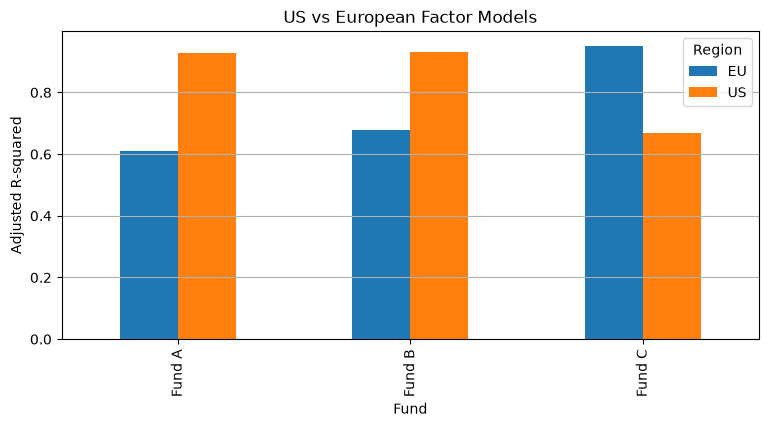

In [28]:
# Compare adjusted R-squared
regional_results['Adjusted R2'].unstack('Region').plot.bar(
    figsize=(9, 4),
    title='US vs European Factor Models'
)

plt.ylabel('Adjusted R-squared')
plt.grid(axis='y')
plt.show()

### Regional Factor Analysis — Main Conclusions

**1. The funds' geographical exposures can be identified from their returns.**

- **Fund A:** US factors explain 92.8% of its return variability, compared with 61.3% for European factors.
- **Fund B:** US factors also provide a substantially better fit (93.5% versus 68.3%).
- **Fund C:** European factors explain 95.1% of its return variability, compared with only 67.4% for US factors.

These results strongly suggest that Funds A and B invest predominantly in US equities, while Fund C has mainly European equity exposure.

**2. Market beta depends on the benchmark.**

Fund C's market beta increases from 0.873 (US model) to 0.970 (European model).

Therefore, a relatively low beta against the US market does not necessarily imply that a fund is defensive. Fund C is almost as sensitive as the European market to European market movements.

**3. Regional factors reveal investment styles more accurately.**

For Fund C, HML changes from an insignificant +0.072 under US factors to a significant −0.177 under European factors, indicating a growth orientation relative to European equities.

**4. An inappropriate benchmark can produce misleading alpha estimates.**

- Fund A's alpha increases from +0.32% monthly (US model) to +1.08% (European model).
- Fund C's alpha changes from −0.34% monthly (US model) to approximately zero (+0.01%) under European factors.

A statistically significant alpha does not necessarily indicate managerial skill if the benchmark fails to capture the fund's relevant risk exposures.

**5. Model selection is essential for investment advice.**

The appropriate regional model provides substantially higher explanatory power and lower residual volatility.

**Overall conclusion:** A financial advisor must select a benchmark consistent with the fund's investment universe before interpreting its beta, investment style, or alpha. Return-based analysis can provide strong evidence about geographical exposure, but cannot uniquely identify the fund's actual holdings.

## 5. What Industries Drive the Funds' Performance?

**Your client asks:**

> We have identified important differences in the investment styles of Funds A and B. However, I would also like to understand the types of businesses driving their returns.
>
> Are these funds primarily exposed to technology, consumer businesses, manufacturing, healthcare, or other industries?
>
> Which industries appear to be most important for each fund? Are these exposures consistent with the investment styles you identified earlier?
>
> How much of each fund's historical behavior can be explained by industry returns?
>
> Finally, can you estimate the exact percentage invested in each industry from this analysis, or would you need additional information?

**Prepare a comparative industry exposure analysis for Funds A and B. Explain the economic interpretation of your results, evaluate their statistical significance, and discuss the limitations of identifying portfolio holdings from historical returns.**

In [29]:
# Select funds and industries
selected_funds = ['Fund A', 'Fund B']
industries = industries_us.columns.tolist()

# Prepare data
industry_excess = industries_us.sub(ff_us['RF'], axis=0)

data = np.expm1(monthly[selected_funds])
data = data.join(ff_us[['RF']]).join(industry_excess).dropna()

# Estimate industry regressions
X = sm.add_constant(data[industries])

results = []

for fund in selected_funds:

    y = data[fund] - data['RF']
    model = sm.OLS(y, X).fit()

    results.append({
        'Fund': fund,
        'Alpha': model.params['const'],
        'Alpha p-value': model.pvalues['const'],
        'Adjusted R2': model.rsquared_adj,
        **model.params[industries].to_dict()
    })

industry_results = pd.DataFrame(results).set_index('Fund')

display(industry_results.round(4))

,Alpha,Alpha p-value,Adjusted R2,Cnsmr,Manuf,HiTec,Hlth,Other
Fund,,,,,,,,
Fund A,0.0018,0.1350,0.9426,0.3648,-0.2406,0.8036,0.0602,0.0919
Fund B,0.0006,0.6646,0.9310,0.1467,0.5696,-0.0346,-0.0071,0.5186


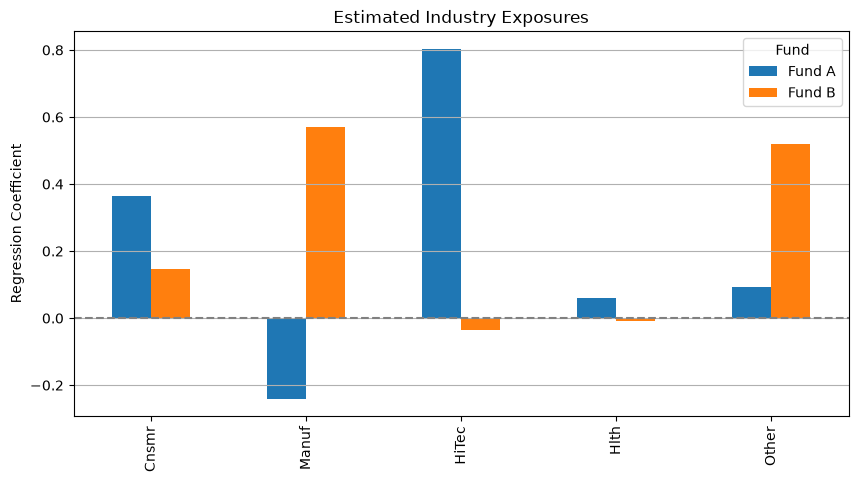

In [30]:
industry_results[industries].T.plot.bar(
    figsize=(10, 5),
    title='Estimated Industry Exposures'
)

plt.ylabel('Regression Coefficient')
plt.axhline(0, color='gray', linestyle='--')
plt.grid(axis='y')
plt.show()

### Industry Exposure Analysis — Main Conclusions

**1. Fund A exhibits strong technology and consumer exposure.**

- Technology: +0.806 (p < 0.01).
- Consumer: +0.337 (p < 0.01).
- Manufacturing: −0.242 (p < 0.01).

These results are consistent with the **large-cap growth investment style** previously identified through the Fama-French model.

**2. Fund B is more exposed to manufacturing and other industries.**

- Manufacturing: +0.593 (p < 0.01).
- Other industries: +0.522 (p < 0.01).
- Technology exposure is not statistically significant.

This pattern differs substantially from Fund A and is compatible with its previously identified value orientation.

**3. Industry portfolios explain most of the funds' historical fluctuations.**

- Fund A: adjusted R² = 94.3%.
- Fund B: adjusted R² = 93.2%.

Industry-based and Fama-French models offer complementary explanations of fund behavior.

**4. Fund A's statistically significant Fama-French alpha disappears in the industry model.**

Fund A's monthly alpha falls from +0.32% (FF3, p = 0.0179) to +0.02% (industry model, p = 0.8382).

This suggests that industry exposures help explain returns not captured by the Fama-French three-factor model. It also illustrates how conclusions about abnormal performance depend on the chosen model.

**5. Industry regression coefficients are not portfolio weights.**

The estimated coefficients measure return sensitivities, not the actual percentage invested in each industry. Identifying exact allocations would require information about the funds' holdings.

**Overall conclusion:** Return-based industry analysis can help identify the economic activities driving fund performance, but it cannot precisely reconstruct portfolio composition or establish managerial skill.

## 6. Do These Risks Change Over Time and Across Market Conditions?

**Your client asks:**

> You have estimated the funds' market sensitivities using historical data. However, I am concerned that these risks may change over time.
>
> Have the funds' market betas remained stable over the past decade? Please show me how they have evolved using five-year rolling windows.
>
> More importantly, I am particularly concerned about market downturns. Do these funds react differently when the US stock market rises and when it falls?
>
> Which fund appears to offer better protection during negative market conditions? Can I rely on these historical relationships when making future investment decisions?

**Prepare an analysis of the funds' changing market sensitivities, comparing their behavior during positive and negative market conditions. Explain the implications for an investor concerned about downside risk and discuss the reliability of your findings.**

In [31]:
# Prepare monthly returns and market factors
data = np.expm1(monthly[funds])
data = data.join(ff_us[['Mkt-RF', 'RF']]).dropna()

# Calculate excess returns
fund_excess = data[funds].sub(data['RF'], axis=0)
market_excess = data['Mkt-RF']

# Calculate rolling betas (60 months)
window = 60

covariance = fund_excess.rolling(window).cov(market_excess)
variance = market_excess.rolling(window).var()

rolling_betas = covariance.div(variance, axis=0).dropna()

display(rolling_betas.tail().round(3))

,Fund A,Fund B,Fund C
Date,,,
2025-08,1.239,1.134,0.836
2025-09,1.242,1.132,0.840
2025-10,1.242,1.142,0.833
2025-11,1.260,1.096,0.799
2025-12,1.259,1.088,0.783


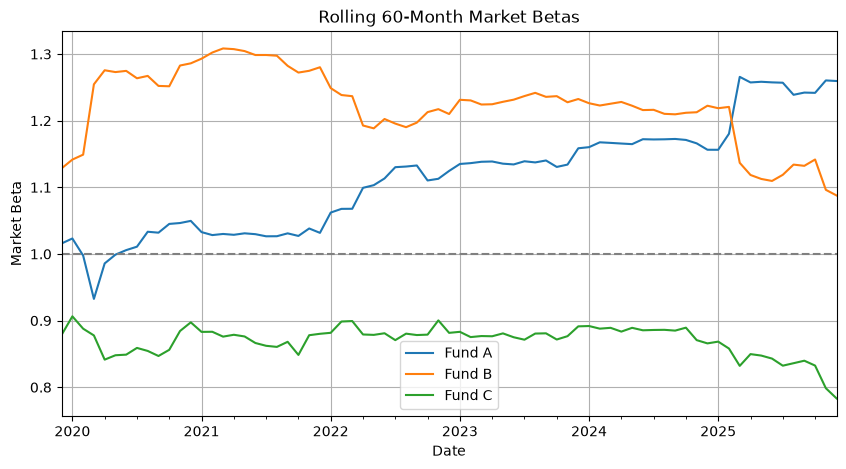

In [32]:
rolling_betas.plot(
    figsize=(10, 5),
    title='Rolling 60-Month Market Betas'
)

plt.axhline(1, color='gray', linestyle='--')
plt.ylabel('Market Beta')
plt.grid()
plt.show()

In [33]:
# Identify up and down market months
markets = {
    'Up': market_excess > 0,
    'Down': market_excess < 0
}

results = []

for market, mask in markets.items():

    # Market returns in the selected months
    X = sm.add_constant(market_excess[mask])

    for fund in funds:

        # Fund excess returns
        y = fund_excess.loc[mask, fund]

        # CAPM regression
        model = sm.OLS(y, X).fit()

        results.append({
            'Fund': fund,
            'Market': market,
            'Alpha': model.params['const'],
            'Beta': model.params['Mkt-RF'],
            'Beta p-value': model.pvalues['Mkt-RF'],
            'R-squared': model.rsquared,
            'Observations': int(model.nobs)
        })

conditional_betas = pd.DataFrame(results).set_index(['Fund', 'Market'])

display(conditional_betas.round(3))

,,Alpha,Beta,Beta p-value,R-squared,Observations
Fund,Market,,,,,
Fund A,Up,0.004,1.176,0.0,0.672,88
Fund B,Up,-0.008,1.299,0.0,0.676,88
Fund C,Up,0.002,0.774,0.0,0.402,88
Fund A,Down,0.000,1.028,0.0,0.661,44
Fund B,Down,0.007,1.304,0.0,0.717,44
Fund C,Down,-0.010,0.714,0.0,0.398,44


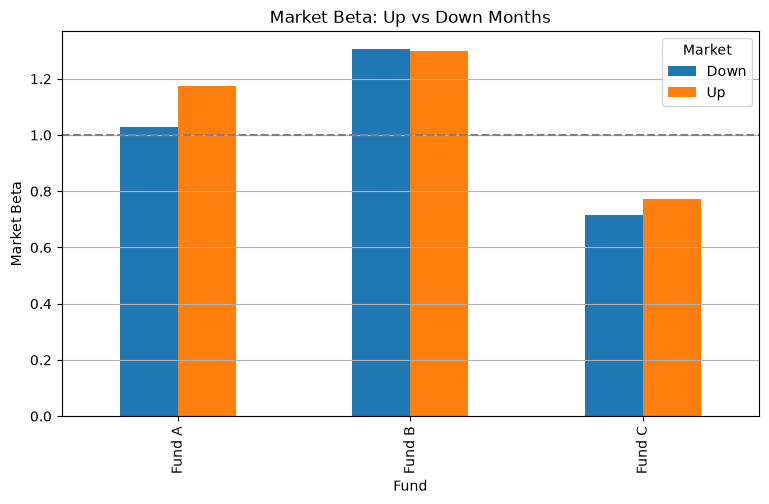

In [34]:
conditional_betas['Beta'].unstack('Market').plot.bar(
    figsize=(9, 5),
    title='Market Beta: Up vs Down Months'
)

plt.ylabel('Market Beta')
plt.axhline(1, color='gray', linestyle='--')
plt.grid(axis='y')
plt.show()

In [15]:

# Test whether up-market and down-market betas differ

results = []

for fund in funds:

    X = pd.DataFrame({
        'Market': market_excess,
        'Down': (market_excess < 0).astype(int),
        'Interaction': market_excess * (market_excess < 0).astype(int)
    })

    reg = sm.OLS(
        fund_excess[fund],
        sm.add_constant(X)
    ).fit(cov_type='HC3')

    results.append({
        'Fund': fund,
        'Beta Up': reg.params['Market'],
        'Beta Down': reg.params['Market'] + reg.params['Interaction'],
        'Difference': reg.params['Interaction'],
        'p-value': reg.pvalues['Interaction']
    })

beta_comparison = pd.DataFrame(results).set_index('Fund')

display(beta_comparison.round(4))


,Beta Up,Beta Down,Difference,p-value
Fund,,,,
Fund A,1.1019,1.0813,-0.0206,0.9281
Fund B,1.2213,1.4143,0.1930,0.4991
Fund C,0.7412,0.7458,0.0047,0.9765


### Time-Varying and Conditional Market Risk — Conclusions

**1. Market betas change over time.**

The 60-month rolling estimates show different patterns:

- **Fund A:** Beta increases from approximately 1.0 to 1.26.
- **Fund B:** Beta declines from levels above 1.2 to 1.08.
- **Fund C:** Beta remains below one, ending at approximately 0.78.

These changes indicate that historical market sensitivity is not necessarily stable. However, rolling estimates alone cannot establish whether these changes are statistically significant.

**2. No statistically significant differences between up-market and down-market betas.**

| Fund | Up-market beta | Down-market beta | Difference p-value |
|---|---:|---:|---:|
| A | 1.102 | 1.081 | 0.928 |
| B | 1.221 | 1.414 | 0.499 |
| C | 0.741 | 0.746 | 0.977 |

Fund B exhibits the largest estimated increase in beta during negative market months (+0.193). However, this difference is not statistically significant.

**We cannot reject the hypothesis of equal up-market and down-market betas for any fund.**

**3. Time variation and market asymmetry are different concepts.**

A fund's market sensitivity can evolve over time without necessarily reacting differently to positive and negative market movements.

**4. Implications for investment advice.**

Historical beta is useful for understanding risk, but it should not be treated as a fixed or reliable prediction of future sensitivity.

Furthermore, Fund C's conditional betas should also be examined using European market factors, given its predominantly European exposure.

**Overall conclusion:** The funds exhibit changes in their rolling market sensitivities, but there is insufficient statistical evidence of asymmetric betas between positive and negative US market months. Investors should not assume that any of these funds provides systematic downside protection based on these estimates alone.

## 7. Your investment recommendation

**Your client asks:**

> I am comparing the three funds for two investors. The first has a long horizon and is prepared to accept substantial short-term losses in pursuit of growth. The second is particularly concerned about large losses and diversification relative to the S&P 500.

> Which fund, if any, would you recommend to each investor? What evidence supports your advice, what risks remain, and what additional information would you request before investing?

Prepare a **300–400-word advisory memo**. Base your recommendation on your analysis rather than on past returns alone. State clearly what cannot be inferred from return data.

In [ ]:
# One-page summary for the client's decision.
summary = performance.loc[funds, ['Annual return', 'Annual volatility', 'Max drawdown']].copy()
summary['Sharpe'] = sharpe[funds]
summary['CAPM beta'] = capm_results['Market beta']
summary['CAPM alpha p-value'] = capm_results['Alpha p-value']
summary['US HML'] = summarize_ff3(ff3_us_models)['HML']
summary['US SMB'] = summarize_ff3(ff3_us_models)['SMB']
display(summary.round(3))

# Instructors should use these results to assess the two client recommendations.
# The notebook deliberately does not classify a fund as objectively "best".

### Suggested instructor answer: advisory assessment

**Confidential identity key:** Fund A = Fidelity Blue Chip Growth Fund (**FBGRX**); Fund B = Fidelity Value Fund (**FDVLX**); Fund C = Fidelity Europe Fund (**FIEUX**).

- **Investor seeking growth, willing to accept substantial drawdowns:** Fund A is a defensible candidate given its growth tilt and strong historical performance. However, its market sensitivity and growth-factor exposure can make it vulnerable to market and valuation shocks. A recommendation should not rely on historical returns alone.
- **Investor concerned with drawdowns and S&P 500 diversification:** Fund C offers a different geographic exposure and typically lower US-market sensitivity than A or B. However, it remains an equity fund, can suffer substantial losses, and market correlation may remain high. Diversification is not protection against all drawdowns.
- **Fund B:** Its smaller-company/value exposures make it a useful alternative for style diversification, but it may not be the right recommendation for a client primarily seeking low downside risk.

**Additional client due diligence:** fees, fund share class, currency, tax treatment, current holdings, investment horizon, drawdown tolerance, and whether the client already holds overlapping US equity exposures. No claim of manager skill follows automatically from an estimated positive alpha, and no fund can be identified uniquely from return patterns.

---

**Data sources:** Kenneth R. French Data Library (US three factors, European three factors and US five-industry portfolios); anonymized fund return series supplied for this assignment.

**Selected literature:** Sharpe (1964), *The Journal of Finance*, 19(3), 425–442; Fama and French (1993), *Journal of Financial Economics*, 33(1), 3–56.